# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [2]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


**Fix 1 — Data file could not be loaded**

- **Error and cause:** The cell stopped with `FileNotFoundError: No such file or directory: '.../data/career_outcome.csv'`. The code asked for `career_outcome.csv`, but the file in the `data` folder is called `career_outcomes.csv` (with an "s"), so Python could not find it.
- **Repair and verification:** I corrected the file name in `pd.read_csv` to `career_outcomes.csv`. I then restarted the kernel and ran all cells: the data loaded (`df.head()` shows the first rows) and all later cells ran without errors.

## Analytic question
**How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.**

- **Outcome:** salary, `salary_k_eur`, in thousands of euros.
- **Predictor:** training hours, `training_hours`.
- **Expected direction:** positive — workers with more training hours are expected to earn more, since training may raise skills and productivity.
- **Plausible omitted variable:** AI tool use (`ai_tool_use`). Workers who use AI tools more may also take more training and earn higher salaries, so part of the training–salary association could reflect AI tool use rather than training itself. Experience and education are other possible omitted variables.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

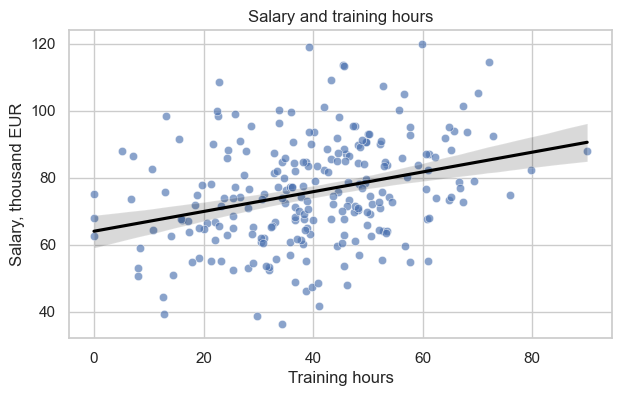

In [3]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [4]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        23:30:18   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [5]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {slope:.4f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 0.2951 thousand EUR


**Fix 2 — Wrong "per hour" effect**

The cell printed 4.75 thousand EUR as the change per additional training hour, but the regression slope is 0.2951. The code multiplied the slope by the standard deviation of training hours (about 16.09), which gives the change for a one-standard-deviation (about 16-hour) increase, not for one hour. I now print the slope itself: one more training hour is associated with about 0.295 thousand EUR (≈ €295) higher salary.

In [6]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "mean_ci_lower", "mean_ci_upper",
                              "obs_ci_lower", "obs_ci_upper"]]).round(2)

,training_hours,mean,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,10,66.92,62.92,70.92,37.15,96.69
1,40,75.78,73.87,77.68,46.22,105.33
2,80,87.58,82.43,92.73,57.64,117.52


**Fix 3 — Wrong interval for predicting new workers**

The original table showed only the confidence interval for the *mean* salary (`mean_ci`), e.g. 73.87–77.68 thousand EUR at 40 hours. That describes the average worker with 40 training hours, not one new worker. For an individual worker the relevant range is the prediction interval (`obs_ci`), which is much wider: about 46.22–105.33 thousand EUR at 40 hours. I added the prediction interval to the table. Training hours alone predict an individual's salary poorly (R² ≈ 0.09). Also, only one worker in the data has 80 or more training hours, so the 80-hour prediction relies on very little data.

[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

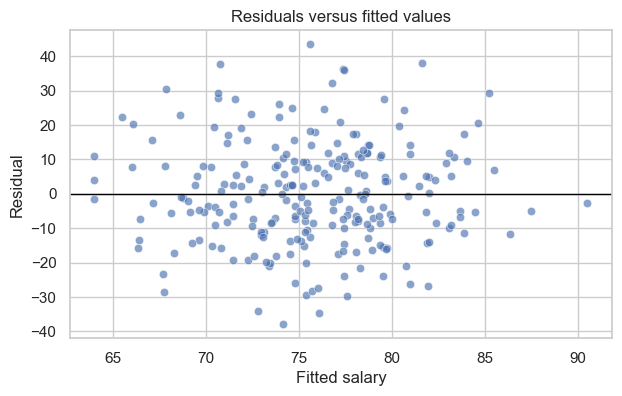

In [7]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

## Interpretation
**State the slope as an association, with units, and name one omitted variable that could confound it.**

The estimated slope is **0.2951 thousand EUR per training hour** (95% CI 0.1765 to 0.4137). On average, workers with one more hour of training earn about 0.295 thousand EUR (≈ €295) more; 10 more hours is associated with about €2,950 higher salary. This is an association, not a causal effect: the model includes only training hours and explains about 9% of the variation in salary (R² ≈ 0.092).

One omitted variable that could confound it is **AI tool use**. In this data it is strongly correlated with training hours (0.62) and with salary (0.40). Workers who use AI tools more tend to train more and earn more, so part of the 0.295 slope may reflect AI tool use rather than training itself, and the slope would likely be smaller if AI tool use were held constant.